# Telco Customer Churn

The IBM Watson Telco Customer Churn dataset. Predicting whether a customer will leave in the next billing cycle. Classes are imbalanced (~27% churn) so I'm careful about how I evaluate — accuracy alone would be misleading.

Plan: light EDA, encode categoricals, baseline logreg, then random forest with class balancing, report precision/recall/F1 + the AUC.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

np.random.seed(2025)
DATA_DIR = Path("../../data/telco_churn")


In [2]:
import urllib.request
CSV = DATA_DIR / "telco_churn.csv"
# IBM's own copy of the Telco Customer Churn sample data (7,043 customers)
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
if not CSV.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL, CSV)
df = pd.read_csv(CSV)
# TotalCharges in the real IBM file ships as strings with a few blanks, so coerce
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
print(df.shape, "churn rate:", (df.Churn == "Yes").mean().round(3))
df.head()

(7043, 21) churn rate: 0.265


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Quick EDA

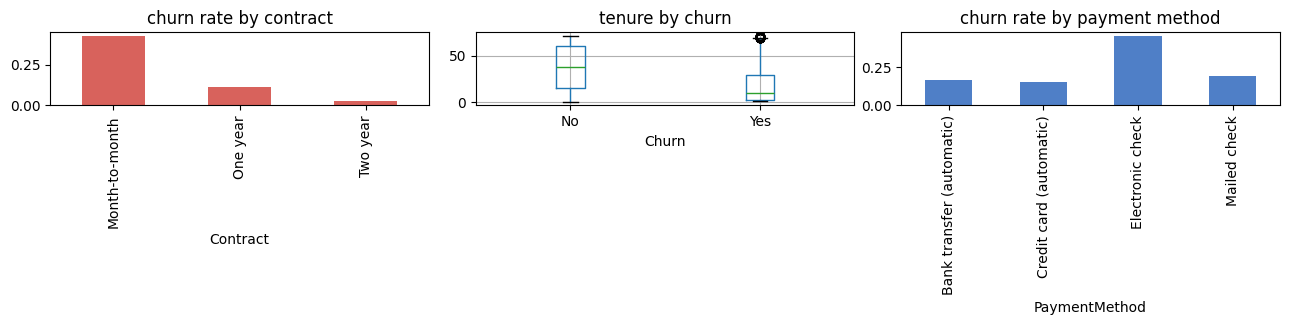

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean()).plot(kind="bar", ax=axes[0], color="#d8625c")
axes[0].set_title("churn rate by contract"); axes[0].set_ylabel("")
df.boxplot(column="tenure", by="Churn", ax=axes[1]); axes[1].set_title("tenure by churn")
df.groupby("PaymentMethod")["Churn"].apply(lambda x: (x == "Yes").mean()).plot(kind="bar", ax=axes[2], color="#4f7fc7")
axes[2].set_title("churn rate by payment method")
plt.suptitle(""); plt.tight_layout(); plt.show()


## Preprocessing

In [4]:
y = (df["Churn"] == "Yes").astype(int).values
drop_cols = ["customerID", "Churn"]
X = pd.get_dummies(df.drop(columns=drop_cols), drop_first=True).astype(float)
feature_names = X.columns.tolist()
X = X.values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=2025
)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
print(f"train={X_train.shape}  test={X_test.shape}")


train=(5634, 30)  test=(1409, 30)


## Modeling

In [5]:
models = {
    "LogReg (balanced)": (LogisticRegression(class_weight="balanced", max_iter=2000), X_train_s, X_test_s),
    "RF (balanced)":     (RandomForestClassifier(n_estimators=400, class_weight="balanced",
                                                 random_state=2025, n_jobs=-1), X_train, X_test),
}

for name, (clf, Xtr, Xte) in models.items():
    clf.fit(Xtr, y_train)
    proba = clf.predict_proba(Xte)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"--- {name} ---")
    print(f"AUC: {roc_auc_score(y_test, proba):.3f}")
    print(classification_report(y_test, pred, target_names=["stay", "churn"]))


--- LogReg (balanced) ---
AUC: 0.842
              precision    recall  f1-score   support

        stay       0.91      0.73      0.81      1035
       churn       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



--- RF (balanced) ---
AUC: 0.818
              precision    recall  f1-score   support

        stay       0.83      0.91      0.87      1035
       churn       0.65      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



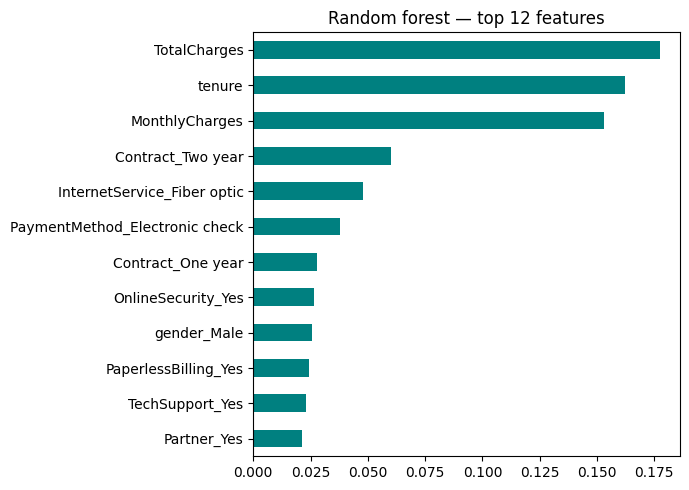

In [6]:
# top RF feature importances — useful as a sanity check
rf = models["RF (balanced)"][0]
imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
imp[::-1].plot(kind="barh", figsize=(7, 5), color="teal")
plt.title("Random forest — top 12 features")
plt.tight_layout(); plt.show()


## Notes

On the full 7,043-customer IBM file (1,409 held out), logistic regression with balanced class weights gets AUC 0.842 and catches 80% of churners at a 0.52 precision. The balanced random forest has a slightly lower AUC (0.818) and at the default 0.5 threshold it is far more conservative, with churn recall of only 0.48. For a retention campaign I'd pick the logistic model or tune the forest's threshold.

What the forest leans on (and what you'd expect from telco churn):

- Tenure and total / monthly charges, the top three by a wide margin. Newer customers leave faster.
- Contract type. Two-year and one-year contracts both show up near the top, which is the flip side of month-to-month being the risky group.
- InternetService = Fiber optic. Counter-intuitive but consistent across many published analyses; usually a cohort effect (fiber customers tend to be price-shopping).
- Payment method (electronic check), a proxy for some underlying customer segment.

A few things I deliberately did not do:
- SMOTE / oversampling. With 26.5% positives plus `class_weight="balanced"` it's not obviously needed.
- Gradient boosting. Would probably nudge AUC up a little; left out to keep this short.
- Threshold tuning. For a real retention campaign you'd care more about the top-N highest-risk customers than 0.5 vs not 0.5.